# El balance poblacional frente a la caminata de reemplazo de partículas de los modelos de elementos discretos de chancadores

**Pregunta:** ¿Reproduce el producto de Whiten la regla de reemplazo que usan los modelos de elementos discretos de chancadores, corrida con la selección y el quiebre propios del producto, y cuántas parcelas muestreadas necesita para hacerlo dentro de un uno por ciento de la masa?

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** el notebook 02 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- decir qué hace el estado del arte de elementos discretos para chancadores, en sus dos familias, y qué aproxima de él el balance poblacional;
- correr una caminata de reemplazo, la regla estocástica en el núcleo de la familia de reemplazo de partículas, con la selección y el quiebre propios del producto;
- comparar el producto de la caminata con el balance de Whiten, y medir el error de muestreo al crecer el número de parcelas;
- declarar con claridad qué reproduce la caminata de la literatura y qué no puede reproducir.

## Preparación

Numpy y matplotlib. Los sorteos vienen del generador de numpy con una semilla fija, de modo que cada corrida da los mismos números.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son las piezas del notebook 02: la selección, la matriz de quiebre y el solucionador de Whiten del motor, que es la referencia con la que se compara la caminata.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import Operating, evaluate, grid_edges, grid_mid
from pipeline.model.crusher.breakage import specific_energy, t10_of, phi_from_t10, breakage_matrix
from pipeline.model.crusher.classification import classification_params, classify
from pipeline.model.crusher.machines import REF_THROW_MM
from pipeline.model.crusher.whiten import whiten_solve
from pipeline.model.crusher.linalg import solve_lu
from pipeline.model.crusher.sieve import to_psd, size_at_passing
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El caso de referencia S01. En este repositorio no hay datos de elementos discretos, de modo que la literatura de abajo se cita y no se corre. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee S01 y corre el motor una vez para obtener la distribución de alimentación en la malla.

In [2]:
# Lea S01, corra el motor una vez para su alimentación y fije la malla
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
result = evaluate(op)
edges, mids = grid_edges(), grid_mid()
K = len(mids)
feed = np.array(result.feed.mass)

print("clases:", K, "| masa de alimentación:", feed.sum().round(12), "| P80 del motor:", round(result.p80, 3), "mm")

clases: 28 | masa de alimentación: 1.0 | P80 del motor: 27.698 mm


## Método

**Armado del modelo.** La comparación necesita el vector de selección $c$, la matriz de quiebre $B$ y el producto de Whiten para cualquier abertura y mineral, así que la celda siguiente empaca la construcción del notebook 02 en una función: la clasificación en cada tamaño medio de clase, la matriz de quiebre a partir del t10 del mineral, y el propio solucionador de Whiten del motor para el producto. Luego los arma para S01.

In [3]:
# Defina el armado de c, B y del producto de Whiten, y constrúyalos para S01
def assemble(css_mm, ore_axb):
    phi = phi_from_t10(t10_of(specific_energy(op.speed_rpm, REF_THROW_MM[op.machine]), ore_axb))
    params = classification_params(op.machine, css_mm, f80_mm=result.f80, calibrated=False, throw_mm=op.throw_mm)
    c = np.array([classify(d, params) for d in mids])
    B = np.array(breakage_matrix(edges, mids, phi)).reshape(K, K)
    return c, B, np.array(whiten_solve(c.tolist(), B.ravel().tolist(), feed.tolist(), K).product)


c, B, reference = assemble(op.css_mm, op.ore_axb)
k = classification_params(op.machine, op.css_mm, f80_mm=result.f80, calibrated=False, throw_mm=op.throw_mm)
print("rango de selección, K1 y K2 de S01 [mm]:", round(k.k1, 2), round(k.k2, 2))

rango de selección, K1 y K2 de S01 [mm]: 29.0 68.4


**El método que se compara.** El modelo de chancador del producto es el balance poblacional del notebook 02: un sistema lineal determinista en el que la selección $C$ y el quiebre $B$ resumen lo que ocurre en la cámara, y el producto es $p = (I - C)(I - BC)^{-1} f$ (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf; Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193). No necesita geometría y corre en milisegundos. La celda imprime el P80 del producto de referencia y la fracción de la masa sobre el borde de clase de 20 mm, los dos números que debe reproducir la caminata.

In [4]:
# Producto de referencia: P80 y la fracción de masa sobre el borde de clase de 20 mm
coarse = [i for i in range(K) if edges[i + 1] >= 19.9]
balance_p80 = size_at_passing(to_psd(edges, reference.tolist()), 0.8)
print("P80 [mm]:", round(balance_p80, 3), "| masa sobre el borde de 20 mm:", round(float(reference[coarse].sum()), 4))

P80 [mm]: 27.698 | masa sobre el borde de 20 mm: 0.2965


## Estado del arte

**La familia de elementos discretos.** El estado del arte para el mecanismo de un chancador es el método de elementos discretos, que resuelve las partículas, sus contactos y su quiebre en la geometría de la cámara. Hay dos familias en las fuentes que cita el producto. En el **reemplazo de partículas**, una partícula que cumple un criterio de quiebre se elimina y se reemplaza por un conjunto de fragmentos menores con tamaños tomados de una distribución de la función de quiebre; Cleary y Sinnott (2015; https://doi.org/10.1016/j.mineng.2014.10.021) la desarrollan para chancadores de compresión. En la familia de **partículas ligadas** la roca es un ensamble de subpartículas y la fractura emerge del modelo de enlaces; Quist y Evertsson (2016; https://doi.org/10.1016/j.mineng.2015.11.004) la calibran con el quiebre de partículas individuales para un chancador de cono. Ambas son herramientas fuera de línea: un paso industrial toma horas de cálculo, por eso el balance poblacional es la aproximación rápida que el estudio corre en vivo.

Hay que decir con exactitud qué se puede correr aquí y qué no. Ni el código ni los datos de ninguna de las dos familias están en este repositorio, de modo que sus números no se reproducen. Lo que ambas comparten con el balance es una lectura estocástica de las mismas dos funciones: una partícula seleccionada se reemplaza por fragmentos sorteados de la distribución de aparición, y un fragmento que sigue seleccionado se quiebra otra vez. Esa regla se puede correr con la $C$ y la $B$ propias del producto, con cada unidad de masa como una parcela para que la caminata siga siendo lineal en la masa. Si reprodujera el balance, el balance sería la esperanza exacta de la regla de reemplazo; la pregunta es si lo hace.

**La caminata de reemplazo.** La celda sortea las parcelas de alimentación desde la distribución de alimentación, y luego repite una sola regla hasta que no queda ninguna parcela en la cámara: cada parcela de la clase $j$ es apretada con probabilidad $c_j$, y una parcela apretada se reemplaza por una parcela de la clase $i$ sorteada con probabilidad $B_{ij}$; una parcela que no es apretada sale y se cuenta en el producto. El ciclo trabaja con conteos de parcelas por clase, de modo que cada pasada es un sorteo binomial por clase y uno multinomial por cada clase apretada, y termina porque cada reemplazo cae estrictamente en una clase más fina. La función devuelve el producto como una distribución.

In [5]:
# La caminata de reemplazo sobre conteos de parcelas por clase, con semilla; devuelve la distribución del producto
def replacement_walk(parcels, seed, c, B):
    rng = np.random.default_rng(seed)
    inside = rng.multinomial(parcels, feed)
    product = np.zeros(K, dtype=np.int64)
    nips = 0
    while inside.sum() > 0:
        nipped = rng.binomial(inside, c)
        product += inside - nipped
        nips += nipped.sum()
        inside = np.zeros(K, dtype=np.int64)
        for j in np.nonzero(nipped)[0]:
            inside += rng.multinomial(nipped[j], B[:, j])
    return product / product.sum(), nips / parcels


walk, nips_per_parcel = replacement_walk(200_000, 42, c, B)
print("mayor diferencia de masa de clase con el producto de Whiten:", np.abs(walk - reference).max().round(5))
print("distancia de variación total:", (0.5 * np.abs(walk - reference).sum()).round(5))

mayor diferencia de masa de clase con el producto de Whiten: 0.00168
distancia de variación total: 0.00372


La caminata con 200 000 parcelas queda a menos de 0,17 puntos porcentuales del balance en cada clase. La figura superpone los dos productos clase por clase. Ambos son cero en las clases gruesas que siempre son apretadas, y ambos ponen el grueso de su masa entre 5 y 40 mm.

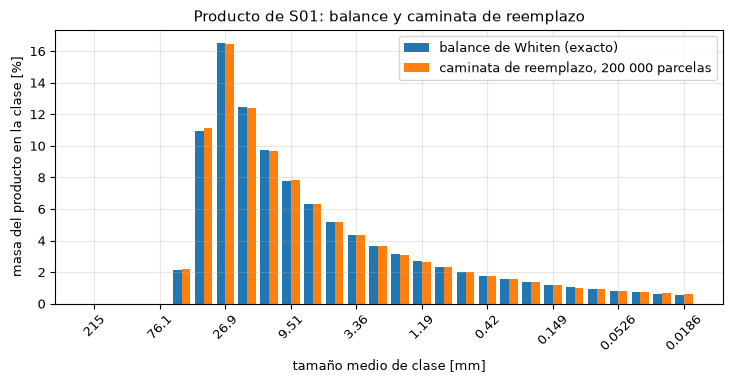

In [6]:
# Gráfico de barras del producto de Whiten y del producto de la caminata de reemplazo por clase
position = np.arange(K)
fig, ax = plt.subplots()
ax.bar(position - 0.2, reference * 100, 0.4, label="balance de Whiten (exacto)")
ax.bar(position + 0.2, walk * 100, 0.4, label="caminata de reemplazo, 200 000 parcelas")
ax.set_xticks(position[::3], [f"{m:.3g}" for m in mids[::3]], rotation=45)
ax.set_xlabel("tamaño medio de clase [mm]")
ax.set_ylabel("masa del producto en la clase [%]")
ax.set_title("Producto de S01: balance y caminata de reemplazo")
ax.legend()
fig.tight_layout()
plt.show()

**Un segundo observable, la recirculación.** El producto es una salida de la caminata; el número de eventos de apriete es otra, y el balance también la predice: es la suma de $c_j x_j$ sobre las clases, la cantidad que el notebook 02 leyó como 0,8858 apriete por unidad de alimentación. La celda resuelve el balance con la rutina LU del motor para esa suma y la compara con el número de apriete por parcela que contó la caminata.

In [7]:
# Eventos de apriete por unidad de alimentación desde el balance (solución LU del motor) frente al conteo propio de la caminata
x = np.array(solve_lu((np.eye(K) - B * c[None, :]).ravel().tolist(), feed.tolist(), K))
print("balance, suma de c x:", round(float((c * x).sum()), 4), "| caminata, apriete por parcela:", round(float(nips_per_parcel), 4))

balance, suma de c x: 0.8858 | caminata, apriete por parcela: 0.8843


Las barras coinciden a simple vista en cada clase, lo que dice que la caminata y el balance son el mismo modelo visto de dos maneras: el balance es la esperanza de la caminata, y la caminata es un muestreo del balance. La imagen no puede mostrar la calidad de la coincidencia, porque una diferencia de 0,17 puntos queda bajo la resolución de las barras. La celda siguiente la mide, en función del número de parcelas, con cinco semillas independientes por tamaño, y la figura que sigue lee la pendiente.

In [8]:
# Distancia de variación total de la caminata al producto de Whiten frente al número de parcelas, cinco semillas cada una
sizes = [10 ** 3, 10 ** 4, 10 ** 5, 10 ** 6]
distance = {n_parcels: [0.5 * np.abs(replacement_walk(n_parcels, seed, c, B)[0] - reference).sum() for seed in range(5)] for n_parcels in sizes}
for n_parcels, values in distance.items():
    print(f"{n_parcels:>9,d} parcelas: mean {np.mean(values):.5f}, min {np.min(values):.5f}, max {np.max(values):.5f}")

    1,000 parcelas: mean 0.05660, min 0.03841, max 0.07280
   10,000 parcelas: mean 0.01649, min 0.01410, max 0.01867
  100,000 parcelas: mean 0.00597, min 0.00396, max 0.00719
1,000,000 parcelas: mean 0.00160, min 0.00136, max 0.00193


La figura grafica la distancia media en ejes logarítmicos frente a la ley de uno sobre raíz cuadrada trazada por el primer punto.

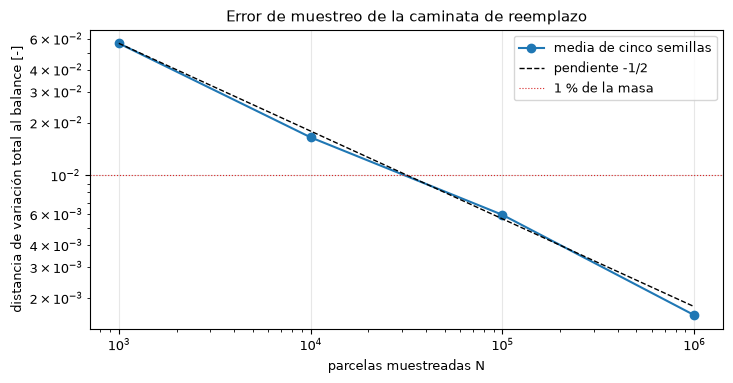

pendiente ajustada: -0.509


In [9]:
# Grafique la distancia media en ejes logarítmicos con la ley 1 / raíz(N) por el primer punto
mean_distance = np.array([np.mean(distance[s]) for s in sizes])
fig, ax = plt.subplots()
ax.loglog(sizes, mean_distance, "o-", label="media de cinco semillas")
ax.loglog(sizes, mean_distance[0] * np.sqrt(sizes[0] / np.array(sizes)), "k--", lw=1, label="pendiente -1/2")
ax.axhline(0.01, color="tab:red", lw=0.8, ls=":", label="1 % de la masa")
ax.set_xlabel("parcelas muestreadas N")
ax.set_ylabel("distancia de variación total al balance [-]")
ax.set_title("Error de muestreo de la caminata de reemplazo")
ax.legend()
fig.tight_layout()
plt.show()
slope = np.polyfit(np.log(sizes), np.log(mean_distance), 1)[0]
print("pendiente ajustada:", round(float(slope), 3))

La distancia medida cae con una pendiente cercana a $-1/2$, la ley del muestreo de Monte Carlo, y cruza la línea de 1 por ciento entre $10^4$ y $10^5$ parcelas. La caminata converge entonces al balance y lo hace a la tasa estándar; no hay sesgo que encontrar con esta resolución. La figura no dice que el balance sea correcto para un chancador real. Dice que el balance es lo que da la regla de reemplazo cuando se le entregan la misma $C$ y la misma $B$, de modo que toda la diferencia entre una simulación de reemplazo de partículas y este producto está en de dónde vienen $C$ y $B$: el DEM las deriva de la mecánica de contacto y de la geometría de la cámara, el producto de las relaciones publicadas y de una calibración.

**¿Sobrevive la equivalencia a otras aberturas y minerales?** Un solo punto de operación podría ser una coincidencia de los números. La celda repite la comparación para tres aberturas de lado cerrado y tres durezas de mineral, nueve combinaciones, cada una con su propio vector de selección y su propia matriz de quiebre armados por la misma función, 100 000 parcelas y una semilla, e imprime la distancia de variación total de la caminata al balance de cada una.

In [10]:
# Distancia de variación total de la caminata al balance para tres aberturas y tres durezas de mineral
print("CSS [mm]   A*b = 30    A*b = 55    A*b = 110")
worst_distance, p80_gap = 0.0, 0.0
for css in (op.css_mm * 0.7, op.css_mm, op.css_mm * 1.3):
    row = []
    for axb in (30, 55, 110):
        cc, BB, ref = assemble(css, axb)
        product_walk = replacement_walk(100_000, 7, cc, BB)[0]
        row.append(0.5 * np.abs(product_walk - ref).sum())
        p80_gap = max(p80_gap, abs(size_at_passing(to_psd(edges, product_walk.tolist()), 0.8) / size_at_passing(to_psd(edges, ref.tolist()), 0.8) - 1))
    worst_distance = max(worst_distance, *row)
    print(f"{css:7.1f}  " + "  ".join(f"{v:10.5f}" for v in row))
print("la peor de las nueve:", round(worst_distance, 5), "| mayor brecha relativa de P80:", f"{p80_gap * 100:.3f} %")

CSS [mm]   A*b = 30    A*b = 55    A*b = 110
   22.4     0.00685     0.00567     0.00523
   32.0     0.00542     0.00478     0.00351
   41.6     0.00519     0.00540     0.00482
la peor de las nueve: 0.00685 | mayor brecha relativa de P80: 0.295 %


Las nueve distancias son del mismo tamaño pequeño, unas milésimas, de modo que la coincidencia es una propiedad de la regla y no de los números de S01. El mineral más duro con la abertura más cerrada necesita más recirculación y da la mayor distancia de la tabla, por tener las caminatas más largas. La última celda traduce la distancia al número que le importa a una planta, el P80 del producto, leído con la misma interpolación del motor, y lo compara con el valor propio del motor.

In [11]:
# P80 del producto de la caminata por la interpolación del motor, frente al P80 del motor
walk_p80 = [size_at_passing(to_psd(edges, replacement_walk(100_000, seed, c, B)[0].tolist()), 0.8) for seed in range(5)]
print("P80 de la caminata con cinco semillas [mm]:", np.round(walk_p80, 3))
print("P80 del motor [mm]:", round(result.p80, 3), "| mayor diferencia relativa:", f"{max(abs(v - result.p80) for v in walk_p80) / result.p80 * 100:.3f} %")

P80 de la caminata con cinco semillas [mm]: [27.811 27.617 27.795 27.704 27.686]
P80 del motor [mm]: 27.698 | mayor diferencia relativa: 0.409 %


## Resultados

**Respuesta:** sí. La caminata de reemplazo corrida con la selección y el quiebre propios del producto reproduce el producto de Whiten: con 200 000 parcelas la mayor diferencia de masa de clase es 0,00168 y la distancia de variación total 0,00372, y la caminata cuenta 0,8843 eventos de apriete por parcela frente a los 0,8858 del balance. La distancia cae con una pendiente ajustada de -0,509 al crecer el número de parcelas, de una media de 0,0165 con 10 000 parcelas a 0,0060 con 100 000, de modo que cruza 1 por ciento de la masa entre ambas. En nueve combinaciones de abertura y mineral la peor distancia es 0,00685 y la peor brecha de P80 0,295 por ciento, y el P80 de cinco caminatas de 100 000 parcelas queda a menos de 0,409 por ciento de los 27,698 mm del motor. Así, el balance es la esperanza exacta de la regla estocástica, y un presupuesto de 100 000 parcelas da el mismo producto con unas pocas décimas de por ciento de la masa.

La primera figura muestra el producto clase por clase, la segunda la ley de convergencia. Un validador concluiría que el modelo rápido del producto y la regla de reemplazo de la familia de elementos discretos coinciden en lo único que este notebook podía probar, el álgebra de seleccionar y quebrar, y que el error de muestreo está controlado. Los límites honestos son tres. La caminata no reproduce ningún número de Cleary y Sinnott (2015) ni de Quist y Evertsson (2016): aquí no hay datos suyos. No tiene geometría, ni mecánica de contacto, ni desgaste, ni formas de partícula, que es lo que una simulación de elementos discretos compra con sus horas de cálculo. Y la coincidencia es de la regla, no de las constantes: si $C$ y $B$ describen un chancador dado se decide frente a mediciones, en los temas 05 y 06.

## Resumen

El balance poblacional y la caminata de reemplazo son un solo modelo en dos formas: el balance es la esperanza exacta, la caminata su muestreo de Monte Carlo, y su diferencia se reduce como el inverso de la raíz de la muestra. Lo que agrega el estado del arte de elementos discretos es la física que produce $C$ y $B$, no un álgebra distinta. El estudio conserva la forma barata, para que un lector pueda mover un control y ver un producto en un milisegundo, y declara con claridad que sus $C$ y $B$ están calibradas, no derivadas. El tema 04 toma el lado de potencia del modelo: capacidad, abertura y energía.

## Referencias

- Cleary, P. W., Sinnott, M. D. (2015), Simulation of particle flows and breakage in crushers using DEM: Part 1 - Compression crushers, Minerals Engineering 74, 178-197. https://doi.org/10.1016/j.mineng.2014.10.021
- Quist, J., Evertsson, C. M. (2016), Cone crusher modelling and simulation using DEM, Minerals Engineering 85, 92-105. https://doi.org/10.1016/j.mineng.2015.11.004
- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193